# When the radio map is wrong

> Power control from a ray-traced map, when the map is not the channel: traced with too few bounces, with the wrong materials, or without the fading on top. Against predictors that learn from what the links measure.

[Power control without channel knowledge](06_predicted_power.ipynb) shows that a ray-traced map, with the
receiver's reported cell and heading, predicts the channel far better than the link's history. That assumes the map
is the channel. A real map is traced from a model of the scene, which is never exact: fewer reflections than the
real channel has, approximate wall materials, and none of the small-scale fading on top.

This example keeps one layout, and gives the transmitter a map that is exact, traced with too few bounces, or traced
with the wrong materials, with or without fading on top. It compares looking the gain up in the map against
learning from what the links measure: a model that uses the map as one input among others, and a map built from
measurements alone.

In [ ]:
import math

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor

from comm_core import *

## The channel and the maps

One FindGoal layout (layout 0 of [Power control on new layouts](07_power_across_layouts.ipynb)). Its channel is
Sionna RT's with 5 bounces. The maps a transmitter could have instead:

* **Exact:** the channel itself.
* **3 bounces:** traced with fewer reflections, as a cheaper trace would be.
* **Wrong materials:** traced with other wall materials than the real ones.

Each scenario also comes with or without small-scale fading on top of the channel, which no map holds: Rayleigh,
redrawn whenever an agent moves, drifting slowly while both stand still.

3 bounces        error  -2.8 ± 9.0 dB; 62 of 1482 cell pairs without any path
wrong materials  error  -1.2 ± 5.8 dB; 0 of 1482 cell pairs without any path


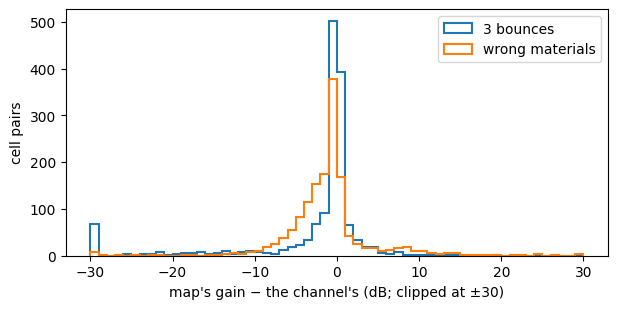

In [ ]:
data = np.load('data/findgoal_layouts.npz')
k0 = list(data['seeds']).index(0)
CELLS = [tuple(int(v) for v in c) for c in data['cells'][k0]]
IDX = {c: i for i, c in enumerate(CELLS)}
to_gain = lambda a: 10 ** (a.astype(float) / 10)
CHANNEL = to_gain(data['gain_db'][k0])                                  # [rx, tx]
MAPS = {'exact': CHANNEL, '3 bounces': to_gain(data['layout0_depth3_gain_db']),
        'wrong materials': to_gain(data['layout0_materials_gain_db'])}
db = lambda g: 10 * np.log10(np.maximum(g, 1e-30))

pairs = ~np.eye(len(CELLS), dtype=bool)
fig, ax = plt.subplots(figsize=(7, 3.2))
for name in ('3 bounces', 'wrong materials'):
    error = (db(MAPS[name]) - db(CHANNEL))[pairs]
    no_path = (MAPS[name][pairs] <= 1e-14).sum()
    print(f'{name:16s} error {error[np.abs(error) < 50].mean():+5.1f} ± {error[np.abs(error) < 50].std():.1f} dB; '
          f'{no_path} of {pairs.sum()} cell pairs without any path')
    ax.hist(np.clip(error, -30, 30), bins=60, range=(-30, 30), histtype='step', lw=1.5, label=name)
ax.set(xlabel="map's gain − the channel's (dB; clipped at ±30)", ylabel='cell pairs')
ax.legend()
plt.show()

## The agents, and what the transmitter knows

Two agents move at random, as in [Power control on new layouts](07_power_across_layouts.ipynb). For each directed
link and step, the transmitter knows the link's last 4 gains, whether it moved and whether the receiver moved a step
ago, and where the receiver was a step ago with its heading: since then, it has stayed or stepped ahead (its
*possible cells*). From the map, it looks up the gain to the receiver's last cell, and the lowest and highest over
its possible cells.

In [ ]:
STEPS, HISTORY = 60, 4
DIRS = [(1, 0), (0, 1), (-1, 0), (0, -1)]

def walk(seed):
    "One episode: per step, both agents' cells and headings."
    rng = np.random.default_rng(seed)
    pos = [CELLS[k] for k in rng.choice(len(CELLS), 2, replace=False)]
    head = [int(h) for h in rng.integers(4, size=2)]
    out = []
    for _ in range(STEPS):
        out.append((tuple(pos), tuple(head)))
        for a in rng.permutation(2):
            action = rng.integers(4)                                     # left, right, forward, nothing
            if action < 2:
                head[a] = (head[a] + (1 if action else -1)) % 4
            elif action == 2:
                ahead = (pos[a][0] + DIRS[head[a]][0], pos[a][1] + DIRS[head[a]][1])
                if ahead in IDX and ahead != pos[1 - a]:
                    pos[a] = ahead
    return out

def fading(episode, seed, rho=0.95):
    "|g_t|² of a pair's Rayleigh fading: redrawn when an agent moves, drifting slowly while both stand still."
    rng = np.random.default_rng(10_000 + seed)
    draw = lambda: (rng.standard_normal() + 1j * rng.standard_normal()) / np.sqrt(2)
    g, out = draw(), []
    for t in range(len(episode)):
        if t and episode[t][0] != episode[t - 1][0]:
            g = draw()
        elif t:
            g = rho * g + np.sqrt(1 - rho ** 2) * draw()
        out.append(abs(g) ** 2)
    return np.array(out)

def samples(seeds, map_name, faded):
    "Per directed link and step: what the transmitter knows (with the map's lookups), and the true gain."
    M, out = MAPS[map_name], []
    for seed in seeds:
        episode = walk(seed)
        fade = fading(episode, seed) if faded else np.ones(len(episode))
        for j, i in ((0, 1), (1, 0)):
            g = [CHANNEL[IDX[cells[i]], IDX[cells[j]]] * f for (cells, _), f in zip(episode, fade)]
            for t in range(HISTORY, len(episode)):
                (now, _), (before, heads), (earlier, _) = episode[t], episode[t - 1], episode[t - 2]
                ahead = (before[i][0] + DIRS[heads[i]][0], before[i][1] + DIRS[heads[i]][1])
                possible = [c for c in (before[i], ahead) if c in IDX and c != now[j]] or [before[i]]
                lookup = [M[IDX[c], IDX[now[j]]] for c in possible]
                out.append(dict(tx=now[j], pair=(now[j], now[i]), possible=possible, past=np.array(g[t - HISTORY:t][::-1]),
                                moved=[float(now[j] != before[j]), float(before[i] != earlier[i])], gain=g[t],
                                map=[M[IDX[before[i]], IDX[now[j]]] if before[i] != now[j] else 1.0, min(lookup), max(lookup)]))
    return out

## The predictors

| predictor | uses | how |
|---|---|---|
| C3-WM's | last 4 gains | linear in `|h|²` (`fit_gain_predictor`, eq. 24) |
| C3-WM's, in dB | last 4 gains | linear in dB |
| map lookup | the map, the receiver's possible cells | the map's lowest gain over the possible cells (`MapChannelInversion`) |
| learned quantile | last 4 gains, moves, the map's lookups | gradient-boosted trees, 5% quantile of the gain in dB |
| measured map | the gains measured in past episodes | each cell pair's mean gain (dB) over the training episodes; pairs never measured from a fit in log-distance; the lowest over the possible cells |

The learned quantile treats the map as one input among others: it learns how far to trust it. The measured map needs
no ray tracing at all, only the layout to stay the same.

In [ ]:
def measured_map(fit):
    "Each cell pair's mean gain in dB over the training transmissions; never measured: a fit in log-distance."
    seen = {}
    for r in fit:
        seen.setdefault(frozenset(r['pair']), []).append(db(r['gain']))
    mean = {k: np.mean(v) for k, v in seen.items()}
    distance = lambda k: math.hypot(*np.subtract(*sorted(k)))
    w = np.polyfit([math.log10(distance(k)) for k in mean], list(mean.values()), 1)
    def gain(a, b):
        k = frozenset((a, b))
        return 10 ** ((mean[k] if k in mean else np.polyval(w, math.log10(math.hypot(a[0] - b[0], a[1] - b[1])))) / 10)
    return gain, len(mean) / (len(CELLS) * (len(CELLS) - 1) / 2)

def predictors(fit):
    "name -> predict(samples) -> ĝ; everything learned from `fit` only."
    y = db(np.array([r['gain'] for r in fit]))
    sequences = [np.r_[r['past'][::-1], r['gain']] for r in fit]
    psi, psi_db = fit_gain_predictor(sequences, history=HISTORY), fit_gain_predictor(sequences, history=HISTORY, domain='db')
    X = lambda rs: np.c_[db(np.stack([r['past'] for r in rs])), db(np.array([r['map'] for r in rs])), [r['moved'] for r in rs]]
    quantile = HistGradientBoostingRegressor(loss='quantile', quantile=0.05, max_iter=400, learning_rate=0.05,
                                             early_stopping=False, random_state=0).fit(X(fit), y)
    measured, coverage = measured_map(fit)
    return {
        "C3-WM's": lambda rs: np.array([max(psi(r['past']), 0.0) for r in rs]),
        "C3-WM's, in dB": lambda rs: np.array([psi_db(r['past']) for r in rs]),
        'map lookup': lambda rs: np.array([r['map'][1] for r in rs]),
        'learned quantile': lambda rs: 10 ** (quantile.predict(X(rs)) / 10),
        'measured map': lambda rs: np.array([min(measured(r['tx'], c) for c in r['possible']) for r in rs]),
    }, coverage

## Judging a predictor

As in [Power control on new layouts](07_power_across_layouts.ipynb): the share of the servable transmissions
(`g ≥ g_min = Γσ²/ρ_max`) reaching `Γ`, and the mean power relative to perfect CSI's. The margin `κ` and the
scheduling threshold `τ` (withhold when `ρ̂ > τ ρ_max`) are chosen on calibration episodes, the cheapest pair
reaching the target there, and the predictors are judged on test episodes. `Γ = 10 dB`, `σ² = −94 dBm`,
`ρ_max = 20 dBm`.

In [ ]:
SNR_TARGET_DB, NOISE_DBM, MAX_POWER_DBM = 10.0, -94.0, 20.0
G_MIN = 10 ** ((SNR_TARGET_DB + NOISE_DBM - MAX_POWER_DBM) / 10)
MARGINS = np.arange(-10, 40.01, 0.25)
TAUS = (0.0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, math.inf)

def outcome(estimate, gain, tau):
    "Per margin: the share of the servable transmissions reaching Γ, the mean power (× perfect CSI's)."
    max_power, servable, need = 1 / G_MIN, gain >= G_MIN, 1 / gain
    rho = 10 ** (MARGINS[:, None] / 10) / np.maximum(estimate, 1e-30)[None, :]
    sent = rho <= max_power * 10 ** (tau / 10) if np.isfinite(tau) else np.ones_like(rho, bool)
    power = np.where(sent, np.minimum(rho, max_power), 0)
    reached = sent & (power >= need * (1 - 1e-9))
    return reached[:, servable].mean(1), power.mean(1) / np.where(servable, need, 0).mean()

def deploy(cal, cal_gain, test, test_gain, target, taus=TAUS):
    "κ and τ chosen on the calibration episodes (the cheapest reaching `target`, else the most reliable); on the test ones."
    best = None
    for tau in taus:
        reached, power = outcome(cal, cal_gain, tau)
        for k in range(len(MARGINS)):
            key = (reached[k] >= target, -power[k] if reached[k] >= target else reached[k])
            if best is None or key > best[0]:
                best = (key, tau, k)
    (met, _), tau, k = best
    reached, power = outcome(test, test_gain, tau)
    return dict(reached=reached[k], power=power[k], met=met, tau=tau, margin=MARGINS[k])

## The comparison

Fit on 200 episodes, calibration on 60 others, test on 60 more:

In [ ]:
SCENARIOS = {'exact map': ('exact', False), 'map traced with 3 bounces': ('3 bounces', False),
             'map with wrong materials': ('wrong materials', False), 'exact map, fading not in it': ('exact', True),
             '3 bounces, and fading': ('3 bounces', True)}
FIT, CALIBRATION, TEST = range(0, 200), range(200, 260), range(1000, 1060)
results = {}
for scenario, (map_name, faded) in SCENARIOS.items():
    fit, cal, test = samples(FIT, map_name, faded), samples(CALIBRATION, map_name, faded), samples(TEST, map_name, faded)
    gains = lambda rs: np.array([r['gain'] for r in rs])
    preds, coverage = predictors(fit)
    results[scenario] = {name: {t: [deploy(p(cal), gains(cal), p(test), gains(test), t, taus=taus) for taus in ((0.0,), TAUS)]
                                for t in (0.95, 0.99)} for name, p in preds.items()}
    print(f'\n{scenario}: {100 * (gains(test) >= G_MIN).mean():.1f}% of the test transmissions servable; '
          f'measured map: {100 * coverage:.0f}% of the cell pairs measured')
    print(f"{'':18s}{'withhold (τ = 0)':>34s}{'tuned τ':>34s}")
    print(f"{'':18s}" + ''.join(f'{100 * t:>16.0f}%' for _ in range(2) for t in (0.95, 0.99)))
    for name, r in results[scenario].items():
        row = [r[t][rule] for rule in (0, 1) for t in (0.95, 0.99)]
        print(f'{name:18s}' + ''.join(f"{100 * d['reached']:8.1f}% {d['power']:5.1f}×{' ' if d['met'] else '✗'}" for d in row))


exact map: 86.2% of the test transmissions servable; measured map: 95% of the cell pairs measured
                                    withhold (τ = 0)                           tuned τ
                                95%              99%              95%              99%
C3-WM's               97.7%  11.0×     98.8%  14.6×✗    97.7%  11.0×     98.8%  14.6×✗
C3-WM's, in dB        89.0%   0.9×✗    89.0%   0.9×✗    96.2%   4.1×     98.6%  10.5× 
map lookup            97.9%   1.0×     97.9%   1.0×✗    97.9%   1.0×     99.7%   4.4× 
learned quantile      97.1%   1.0×✗    97.1%   1.0×✗    97.8%   1.3×     99.6%   4.4× 
measured map          91.3%   1.0×✗    91.3%   1.0×✗    97.9%   3.8×     99.7%   7.6× 



map traced with 3 bounces: 86.2% of the test transmissions servable; measured map: 95% of the cell pairs measured
                                    withhold (τ = 0)                           tuned τ
                                95%              99%              95%              99%
C3-WM's               97.7%  11.0×     98.8%  14.6×✗    97.7%  11.0×     98.8%  14.6×✗
C3-WM's, in dB        89.0%   0.9×✗    89.0%   0.9×✗    96.2%   4.1×     98.6%  10.5× 
map lookup            87.6%   1.0×✗    87.6%   1.0×✗    95.9%   6.8×     98.5%   7.3× 
learned quantile      88.8%   0.6×✗    88.8%   0.6×✗    96.8%   4.0×     99.0%   6.2× 
measured map          91.3%   1.0×✗    91.3%   1.0×✗    97.9%   3.8×     99.7%   7.6× 



map with wrong materials: 86.2% of the test transmissions servable; measured map: 95% of the cell pairs measured
                                    withhold (τ = 0)                           tuned τ
                                95%              99%              95%              99%
C3-WM's               97.7%  11.0×     98.8%  14.6×✗    97.7%  11.0×     98.8%  14.6×✗
C3-WM's, in dB        89.0%   0.9×✗    89.0%   0.9×✗    96.2%   4.1×     98.6%  10.5× 
map lookup            90.9%   1.5×✗    90.9%   1.5×✗    98.2%   5.7×     99.2%   6.6× 
learned quantile      90.5%   0.7×✗    90.5%   0.7×✗    97.6%   3.7×     99.6%   6.2× 
measured map          91.3%   1.0×✗    91.3%   1.0×✗    97.9%   3.8×     99.7%   7.6× 



exact map, fading not in it: 85.9% of the test transmissions servable; measured map: 95% of the cell pairs measured
                                    withhold (τ = 0)                           tuned τ
                                95%              99%              95%              99%
C3-WM's               96.0%   8.3×     97.2%   9.9×✗    95.7%   7.9×     97.4%   9.9×✗
C3-WM's, in dB        83.8%   0.9×✗    83.8%   0.9×✗    95.3%   4.7×     98.7%  10.1× 
map lookup            83.4%   1.5×✗    83.4%   1.5×✗    95.5%   5.5×     98.7%   8.7× 
learned quantile      86.0%   1.1×✗    86.0%   1.1×✗    96.5%   4.5×     98.8%   7.5× 
measured map          83.3%   1.8×✗    83.3%   1.8×✗    95.9%   6.1×     99.0%   9.4× 



3 bounces, and fading: 85.9% of the test transmissions servable; measured map: 95% of the cell pairs measured
                                    withhold (τ = 0)                           tuned τ
                                95%              99%              95%              99%
C3-WM's               96.0%   8.3×     97.2%   9.9×✗    95.7%   7.9×     97.4%   9.9×✗
C3-WM's, in dB        83.8%   0.9×✗    83.8%   0.9×✗    95.3%   4.7×     98.7%  10.1× 
map lookup            79.6%   1.3×✗    79.6%   1.3×✗    93.9%   7.2×     98.5%   8.9× 
learned quantile      83.7%   1.0×✗    83.7%   1.0×✗    96.3%   4.9×     98.8%   8.0× 
measured map          83.3%   1.8×✗    83.3%   1.8×✗    95.9%   6.1×     99.0%   9.4× 


* **With an exact map, the lookup reaches 95% at perfect CSI's power,** with no margin: the receiver's actual cell is
  one of its possible cells, so the lookup never overestimates. 99% costs 4.4×, because of the receiver's position,
  not the map. In about 2% of the transmissions, one possible cell is beyond the budget while the cell the receiver
  went to is not. Sending those takes a large threshold `τ`, and then the transmitter also spends `ρ_max` on the
  14% of transmissions that can't be served.
* **An imperfect map makes the lookup the worst map-based predictor.** Traced with 3 bounces (−2.8 ± 9.0 dB off,
  and 62 cell pairs without any path), it needs 6.8× for 95%. With the wrong materials (−1.2 ± 5.8 dB off), 5.7×.
  The learned quantile, given the same map, needs 4.0× and 3.7×: it learns how far to trust the map.
* **The measured map needs no ray tracing:** 3.8× for 95% and 7.6× for 99%, with 95% of the cell pairs measured in
  200 episodes. That is as good as a wrong map used well. It holds only while the layout stays the same.
* **Fading the map doesn't hold costs everyone,** the exact map included: 4.5–7.2× for 95%, 7.5–10× for 99%. The
  learned quantile is the cheapest at 99%; at 95%, it is within 5% of the cheapest.
* **C3-WM's predictor** (linear in `|h|²`) never reaches 99%, and needs 8–11× for 95%. Withholding as soon as
  `ρ̂ > ρ_max` (`τ = 0`) meets 95% on the calibration episodes only with the exact map's lookup, and with C3-WM's
  predictor, which rarely predicts more than `ρ_max`.

## In short

* **An exact map is worth using directly:** the lookup over the receiver's possible cells needs no margin. Most of
  what remains is the receiver's position, which a fresher report would reduce.
* **An imperfect map is worth learning from, not looking up.** Given the map as an input, a learned quantile model
  is the cheapest at 99% in every scenario with an imperfect map or with fading, and within about 5% of the cheapest
  at 95%.
* **Without any ray tracing, measure the map,** if the layout stays the same. When it changes from episode to
  episode, see [Power control on new layouts](07_power_across_layouts.ipynb).

In [ ]:
tuned = lambda scenario, name, target: results[scenario][name][target][1]
assert tuned('exact map', 'map lookup', 0.95)['power'] < 1.2                               # an exact map: no margin needed
for scenario in ('map traced with 3 bounces', 'map with wrong materials', 'exact map, fading not in it', '3 bounces, and fading'):
    assert tuned(scenario, 'learned quantile', 0.99)['power'] < tuned(scenario, 'map lookup', 0.99)['power']   # learn from a wrong map
    assert tuned(scenario, 'learned quantile', 0.95)['power'] < tuned(scenario, 'map lookup', 0.95)['power']
assert not any(tuned(s, "C3-WM's", 0.99)['met'] for s in SCENARIOS)